In [2]:
!wget -O chinook.db https://github.com/lerocha/chinook-database/releases/download/v1.4.5/Chinook_Sqlite.sqlite

--2026-11-15 14:00:37--  https://github.com/lerocha/chinook-database/releases/download/v1.4.5/Chinook_Sqlite.sqlite
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/26098045/f874d47d-29a1-4df5-9784-b25c33a86bc8?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-15T14%3A56%3A47Z&rscd=attachment%3B+filename%3DChinook_Sqlite.sqlite&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-15T13%3A55%3A53Z&ske=2026-11-15T14%3A56%3A47Z&sks=b&skv=2018-11-09&sig=DiDk78RRb99tF9DVrFxlhERWpG5wxmYhuUt5%2BmqOB%2FQ%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NDc1MTUxMCwibmJmIjoxNzk0NzUxMjEwLCJwYXRoIjoicmVsZWFzZWFzc2

In [4]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("chinook.db")

def run(query):
    return pd.read_sql(query, conn)

In [5]:
run("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


In [7]:
run("SELECT * FROM Invoice LIMIT 3")

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2009-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,None,Germany,70174,1.98
1,2,4,2009-01-02 00:00:00,Ullevålsveien 14,Oslo,None,Norway,0171,3.96
2,3,8,2009-01-03 00:00:00,Grétrystraat 63,Brussels,None,Belgium,1000,5.94


In [8]:
run("SELECT * FROM InvoiceLine LIMIT 3")

,InvoiceLineId,InvoiceId,TrackId,UnitPrice,Quantity
0,1,1,2,0.99,1
1,2,1,4,0.99,1
2,3,2,6,0.99,1


In [9]:
run("""
SELECT c.FirstName, c.LastName, i.InvoiceId, i.Total
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
LIMIT 5
""")

,FirstName,LastName,InvoiceId,Total
0,Leonie,Köhler,1,1.98
1,Bjørn,Hansen,2,3.96
2,Daan,Peeters,3,5.94
3,Mark,Philips,4,8.91
4,John,Gordon,5,13.86


In [10]:
run("""
SELECT c.FirstName, c.LastName, SUM(i.Total) AS total_spent
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
GROUP BY c.CustomerId
ORDER BY total_spent DESC
LIMIT 5
""")

,FirstName,LastName,total_spent
0,Helena,Holý,49.62
1,Richard,Cunningham,47.62
2,Luis,Rojas,46.62
3,Ladislav,Kovács,45.62
4,Hugh,O'Reilly,45.62


In [11]:
run("""
SELECT g.Name AS genre, ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Genre g ON t.GenreId = g.GenreId
GROUP BY g.GenreId
ORDER BY revenue DESC
LIMIT 5
""")

,genre,revenue
0,Rock,826.65
1,Latin,382.14
2,Metal,261.36
3,Alternative & Punk,241.56
4,TV Shows,93.53


In [12]:
run("""
SELECT strftime('%Y-%m', InvoiceDate) AS month, ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY month
ORDER BY month
""")


,month,revenue
0,2009-01,35.64
1,2009-02,37.62
2,2009-03,37.62
3,2009-04,37.62
4,2009-05,37.62
5,2009-06,37.62
6,2009-07,37.62
7,2009-08,37.62
8,2009-09,37.62
9,2009-10,37.62


In [13]:
run("""
SELECT c.FirstName, c.LastName, ROUND(SUM(i.Total), 2) AS total_spent
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
GROUP BY c.CustomerId
HAVING SUM(i.Total) > (
    SELECT AVG(cust_total) FROM (
        SELECT SUM(Total) AS cust_total FROM Invoice GROUP BY CustomerId
    )
)
ORDER BY total_spent DESC
""")

,FirstName,LastName,total_spent
0,Helena,Holý,49.62
1,Richard,Cunningham,47.62
2,Luis,Rojas,46.62
3,Ladislav,Kovács,45.62
4,Hugh,O'Reilly,45.62
5,Frank,Ralston,43.62
6,Julia,Barnett,43.62
7,Fynn,Zimmermann,43.62
8,Astrid,Gruber,42.62
9,Victor,Stevens,42.62


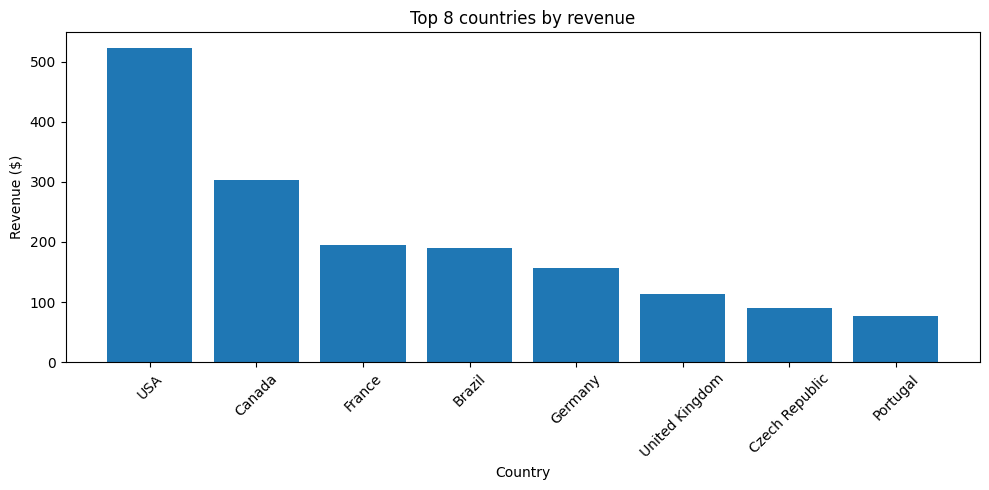

In [14]:
import matplotlib.pyplot as plt

data = run("""
SELECT BillingCountry, ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY BillingCountry
ORDER BY revenue DESC
LIMIT 8
""")

plt.figure(figsize=(10, 5))
plt.bar(data["BillingCountry"], data["revenue"])
plt.title("Top 8 countries by revenue")
plt.xlabel("Country")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("revenue_by_country.png")
plt.show()

In [15]:
above_avg = run("""
SELECT c.FirstName, c.LastName, ROUND(SUM(i.Total), 2) AS total_spent
FROM Invoice i
JOIN Customer c ON i.CustomerId = c.CustomerId
GROUP BY c.CustomerId
HAVING SUM(i.Total) > (
    SELECT AVG(cust_total) FROM (
        SELECT SUM(Total) AS cust_total FROM Invoice GROUP BY CustomerId
    )
)
ORDER BY total_spent DESC
""")

print(len(above_avg))

22


In [16]:
run("""
SELECT COUNT(*) AS customers_above_average
FROM (
    SELECT CustomerId, SUM(Total) AS total_spent
    FROM Invoice
    GROUP BY CustomerId
    HAVING SUM(Total) > (
        SELECT AVG(cust_total) FROM (
            SELECT SUM(Total) AS cust_total FROM Invoice GROUP BY CustomerId
        )
    )
)
""")

,customers_above_average
0,22


In [6]:
run("SELECT * FROM Customer LIMIT 3")

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,None,Theodor-Heuss-Straße 34,Stuttgart,None,Germany,70174,+49 0711 2842222,None,leonekohler@surfeu.de,5
2,3,François,Tremblay,None,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,None,ftremblay@gmail.com,3
